# Kenya maize and fertilizer prices by county, 2026

Monthly median prices for dry maize, dry beans, Irish potatoes and fertilizer in 16 Kenyan counties, January to October 2026, in Kenyan shillings per kilogram. The prices are the official market records of Kenya's Agricultural Market Information System (Ministry of Agriculture), read daily by [NuaSense](https://agriculture-data.com).

This notebook answers four questions: where maize is cheapest, how many kilograms of maize a farmer must sell for one bag of DAP, how far retail sits above wholesale, and how the maize price moved through the year.

The data is a free sample, also on [Hugging Face](https://huggingface.co/datasets/nuasense/kenya-county-food-and-fertilizer-prices) (CC BY-NC 4.0). The last cell shows how to get the full series.

In [1]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt

HF = "https://huggingface.co/datasets/nuasense/kenya-county-food-and-fertilizer-prices/resolve/main/data"

def load(name, hf_path):
    # On Kaggle the file sits under /kaggle/input; in Colab or on your machine it is read from Hugging Face.
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"**/{name}", recursive=True)
    return pd.read_parquet(hits[0] if hits else f"{HF}/{hf_path}/{name}")

prices = load("kenya_county_prices_monthly_2026.parquet", "prices")
county_month = load("kenya_county_month_2026.parquet", "county_month")
print(len(prices), "price rows,", prices.county_id.nunique(), "counties,", prices.month.min(), "to", prices.month.max())
prices.head()

898 price rows, 16 counties, 2026-01 to 2026-10


,county_name,county_id,month,commodity,variety,price_type,median_kes_per_kg,observations,markets
0,Bomet,bomet,2026-01,beans_dry,all,retail,175.00,14,4
1,Bomet,bomet,2026-01,beans_dry,all,wholesale,136.11,14,4
2,Bomet,bomet,2026-01,maize_dry,all,retail,65.00,14,5
3,Bomet,bomet,2026-01,maize_dry,all,wholesale,48.89,14,5
4,Bomet,bomet,2026-01,potatoes_irish,all,retail,60.00,3,2


## Where is maize cheapest?

The latest month with a recorded retail price, per county.

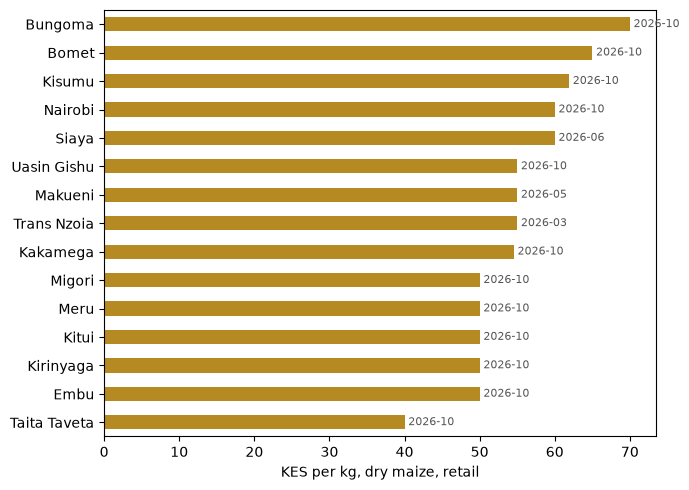

In [2]:
maize = prices[(prices.commodity == "maize_dry") & (prices.price_type == "retail")]
latest = maize.sort_values("month").groupby("county_name").tail(1).sort_values("median_kes_per_kg")
ax = latest.plot.barh(x="county_name", y="median_kes_per_kg", legend=False, figsize=(7, 5), color="#b58a23")
ax.set_xlabel("KES per kg, dry maize, retail"); ax.set_ylabel("")
for i, (v, m) in enumerate(zip(latest.median_kes_per_kg, latest.month)):
    ax.text(v + 0.5, i, m, va="center", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

## How many kilograms of maize buy one bag of DAP?

A 50 kg bag of DAP at the county's retail price, divided by the retail price of a kilogram of maize in the same month. Fertilizer is recorded in fewer counties and months than maize, so this exists for fewer rows.

In [3]:
bag = county_month.dropna(subset=["kg_maize_per_dap_bag"])[["county_name", "month", "dap_retail", "maize_retail", "kg_maize_per_dap_bag"]]
print(len(bag), "county-months with both prices")
bag.sort_values(["county_name", "month"]).tail(15)

35 county-months with both prices


,county_name,month,dap_retail,maize_retail,kg_maize_per_dap_bag
44,Kirinyaga,2026-09,140.0,50.00,140.0
45,Kirinyaga,2026-10,140.0,50.00,140.0
46,Kisumu,2026-01,130.0,60.00,108.3
47,Kisumu,2026-02,110.0,65.00,84.6
48,Kisumu,2026-03,136.0,65.00,104.6
49,Kisumu,2026-04,136.0,65.00,104.6
50,Kisumu,2026-05,120.0,65.84,91.1
51,Kisumu,2026-06,136.0,65.00,104.6
52,Kisumu,2026-07,136.0,60.00,113.3
53,Kisumu,2026-08,136.0,60.00,113.3


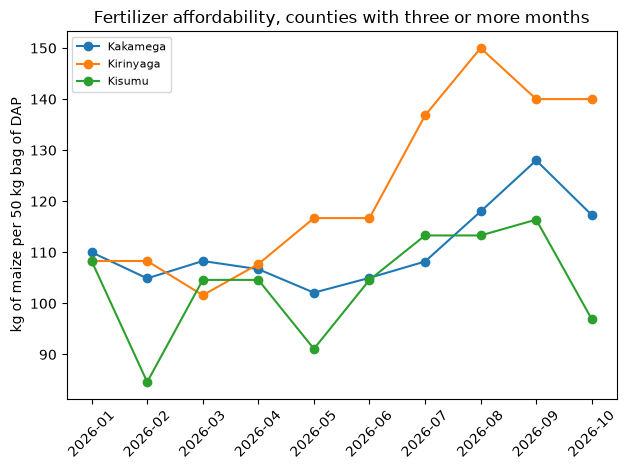

In [4]:
for county, g in bag.groupby("county_name"):
    if len(g) >= 3:
        plt.plot(g.month, g.kg_maize_per_dap_bag, marker="o", label=county)
plt.ylabel("kg of maize per 50 kg bag of DAP"); plt.xticks(rotation=45); plt.legend(fontsize=8)
plt.title("Fertilizer affordability, counties with three or more months"); plt.tight_layout(); plt.show()

## Retail over wholesale

The gap between what a consumer pays and what a trader pays for the same kilogram of maize, in the latest month both were recorded.

In [5]:
w = prices[(prices.commodity == "maize_dry")].pivot_table(index=["county_name", "month"], columns="price_type", values="median_kes_per_kg").dropna().reset_index()
w = w.sort_values("month").groupby("county_name").tail(1)
w["margin_pct"] = (w.retail / w.wholesale - 1) * 100
w.sort_values("margin_pct", ascending=False)[["county_name", "month", "wholesale", "retail", "margin_pct"]].round(1)

price_type,county_name,month,wholesale,retail,margin_pct
15,Bungoma,2026-10,40.0,70.0,75.0
24,Embu,2026-10,32.0,50.0,56.2
9,Bomet,2026-10,50.0,65.0,30.0
54,Kisumu,2026-10,50.0,61.9,23.8
34,Kakamega,2026-10,44.4,54.6,22.7
85,Siaya,2026-06,50.0,60.0,20.0
58,Kitui,2026-10,42.2,50.0,18.4
84,Nairobi,2026-10,51.1,60.0,17.4
97,Trans Nzoia,2026-03,47.2,55.0,16.5
94,Taita Taveta,2026-10,35.0,40.0,14.3


## The maize price through 2026

The five counties with the most months of retail prices.

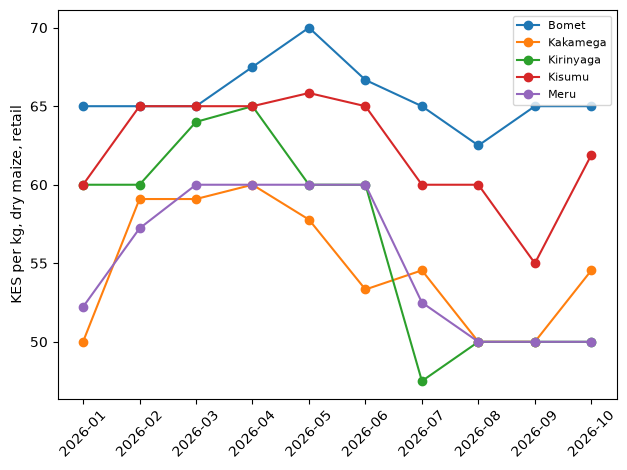

In [6]:
top = maize.groupby("county_name").month.nunique().sort_values(ascending=False).head(5).index
for county in top:
    g = maize[maize.county_name == county].sort_values("month")
    plt.plot(g.month, g.median_kes_per_kg, marker="o", label=county)
plt.ylabel("KES per kg, dry maize, retail"); plt.xticks(rotation=45); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

## The full series

This sample holds monthly medians for four products. The NuaSense API serves every recorded price by market and day since May 2021, for 195 commodities and all 47 counties, plus asking prices, coffee and tea auctions and ready-made analyses such as county rank and affordability.

```
pip install nuasense
```

A key with a free monthly allowance comes from [platform.nuasense.com](https://platform.nuasense.com/start). On Kaggle, store it as a secret named `NUASENSE_API_KEY` (Add-ons → Secrets). Field lists and filters: [agriculture-data.com](https://agriculture-data.com/datasets/price-intelligence/commodity-prices/).

In [7]:
# Runs only when a NuaSense key is available (Kaggle secret or environment variable).
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("NUASENSE_API_KEY", UserSecretsClient().get_secret("NUASENSE_API_KEY"))
except Exception:
    pass

if os.environ.get("NUASENSE_API_KEY"):
    import nuasense  # pip install nuasense
    ns = nuasense.Client()
    daily = pd.DataFrame(ns.rows("/market/prices", start="-30d", commodity="fertilizer", variety="dap", county="kakamega", source="kamis"))
    display(daily.head())
else:
    print("No NUASENSE_API_KEY set: add it as a Kaggle secret to read the daily series.")

No NUASENSE_API_KEY set: add it as a Kaggle secret to read the daily series.
